<a href="https://colab.research.google.com/github/narendra2006/EDA_E-CommerceIndonesia/blob/main/UTS_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# menginstall dependensi dan library yang dibutuhkan
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import os

**Data Collection**

In [2]:
# mengambil dataset dari web kaggle secara langsung
path = kagglehub.dataset_download("zkyfauzi/indonesia-ecommerce-sales")
read_file = os.listdir(path)

# mencari file csv dan merapikan tabel dengan separator semicolon
csv_path = os.path.join(path, read_file[0])
data = pd.read_csv(csv_path, sep=';')

100%|██████████| 458k/458k [00:00<00:00, 579kB/s]

Extracting files...


**Data Understanding**

In [3]:
data.head()

,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,order_date
0,ORD_0000001,2.0,2000,0,0,Celengan,1,Selesai,Tidak dibatalkan,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15,2024-04-01
1,ORD_0000002,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47,2024-04-01
2,ORD_0000003,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25,2024-04-01
3,ORD_0000004,2.0,400,0,0,Mangkok Sambal / Saus,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41,2024-04-01
4,ORD_0000005,3.0,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12,2024-04-01


In [4]:
data.tail()

,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,order_date
18863,ORD_0020844,2.0,200,0,0,Seal / Baut / Roof,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,Online Payment,KAB. BOGOR,JAWA BARAT,0,3500,37500,3500,2025-09-30 21:30,2025-09-30
18864,ORD_0020845,2.0,160,0,0,Aksesoris Pintu,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KAB. KARAWANG,JAWA BARAT,0,3500,15000,3500,2025-09-30 21:35,2025-09-30
18865,ORD_0020846,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SPayLater,KOTA BANDAR LAMPUNG,LAMPUNG,1000,15000,20000,16000,2025-09-30 22:33,2025-09-30
18866,ORD_0020847,1.0,80,0,0,Aksesoris Pintu,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SPayLater,KOTA BANDUNG,JAWA BARAT,0,3500,9000,3500,2025-09-30 23:39,2025-09-30
18867,ORD_0020848,2.0,400,0,0,Mangkok Sambal / Saus,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KAB. BEKASI,JAWA BARAT,0,3500,32000,3500,2025-09-30 23:57,2025-09-30


In [5]:
data.shape

(18868, 19)

In [6]:
data.describe()

,total_qty,total_weight_gr,total_returned_qty,Total Diskon,num_product_categories,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim
count,18585.000000,18868.000000,18868.000000,18868.000000,18868.000000,18868.000000,18868.000000,1.886800e+04,18868.000000
mean,2.565940,2021.273055,0.018709,424.220691,1.113473,4312.362678,10605.738552,5.099066e+04,18446.542612
std,7.799706,7044.934507,0.575668,10110.492750,0.491409,13900.862394,12482.329140,1.426189e+05,23076.099280
min,1.000000,10.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000e+00,1.000000
25%,1.000000,300.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.367500e+04,8000.000000
50%,1.000000,500.000000,0.000000,0.000000,1.000000,0.000000,9000.000000,2.180000e+04,11000.000000
75%,2.000000,1600.000000,0.000000,0.000000,1.000000,3000.000000,15000.000000,4.231125e+04,20000.000000
max,256.000000,375000.000000,70.000000,700000.000000,11.000000,584000.000000,312000.000000,3.076000e+06,624000.000000


In [7]:
data.columns

Index(['order_id', 'total_qty', 'total_weight_gr', 'total_returned_qty',
       'Total Diskon', 'product_categories', 'num_product_categories',
       'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman',
       'Metode Pembayaran', 'Kota/Kabupaten', 'Provinsi',
       'Ongkos Kirim Dibayar oleh Pembeli',
       'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran',
       'Perkiraan Ongkos Kirim', 'Waktu Pesanan Dibuat', 'order_date'],
      dtype='object')

In [8]:
data.dtypes

,0
order_id,object
total_qty,float64
total_weight_gr,int64
total_returned_qty,int64
Total Diskon,int64
product_categories,object
num_product_categories,int64
Status Pesanan,object
Alasan Pembatalan,object
Opsi Pengiriman,object


**Data Standardizing**

In [9]:
# menyamakan format pada nama fitur dari mengganti spasi dengan undescrore dan merubah semua huruf jadi lowercase
data = data.rename(columns={
    'Total Diskon': 'total_diskon',
    'Status Pesanan': 'status_pesanan',
    'Alasan Pembatalan': 'alasan_pembatalan',
    'Opsi Pengiriman': 'opsi_pengiriman',
    'Metode Pembayaran': 'metode_pembayaran',
    'Kota/Kabupaten': 'kota_kabupaten',
    'Provinsi': 'provinsi',
    'Ongkos Kirim Dibayar oleh Pembeli': 'ongkir_pembeli',
    'Estimasi Potongan Biaya Pengiriman': 'estimasi_potongan_ongkir',
    'Total Pembayaran': 'total_pembayaran_ribuan',
    'Perkiraan Ongkos Kirim': 'perkiraan_ongkir',
    'Waktu Pesanan Dibuat': 'waktu_pesanan_dibuat'
})

print(data.columns)

Index(['order_id', 'total_qty', 'total_weight_gr', 'total_returned_qty',
       'total_diskon', 'product_categories', 'num_product_categories',
       'status_pesanan', 'alasan_pembatalan', 'opsi_pengiriman',
       'metode_pembayaran', 'kota_kabupaten', 'provinsi', 'ongkir_pembeli',
       'estimasi_potongan_ongkir', 'total_pembayaran_ribuan',
       'perkiraan_ongkir', 'waktu_pesanan_dibuat', 'order_date'],
      dtype='object')


In [10]:
# menerjemahkan sisa nama fitur yang masih berbahasa Inggris menjadi bahasa Indonesia
data = data.rename(columns={
    'order_id': 'id_pesanan',
    'total_qty': 'total_kuantitas',
    'total_weight_gr': 'total_berat_kg',
    'total_returned_qty': 'total_jumlah_retur',
    'product_categories': 'kategori_produk',
    'num_product_categories': 'jumlah_kategori_produk',
    'order_date': 'tanggal_pesanan'
})

print(data.columns)

Index(['id_pesanan', 'total_kuantitas', 'total_berat_kg', 'total_jumlah_retur',
       'total_diskon', 'kategori_produk', 'jumlah_kategori_produk',
       'status_pesanan', 'alasan_pembatalan', 'opsi_pengiriman',
       'metode_pembayaran', 'kota_kabupaten', 'provinsi', 'ongkir_pembeli',
       'estimasi_potongan_ongkir', 'total_pembayaran_ribuan',
       'perkiraan_ongkir', 'waktu_pesanan_dibuat', 'tanggal_pesanan'],
      dtype='object')


In [11]:
# mengubah satuan berat dari gram ke kilogram
data['total_berat_kg'] = data['total_berat_kg'] / 1000

In [12]:
# Membuat kolom baru 'tipe_pengiriman' berdasarkan kategorinya
kondisi_tipe = [
    data['opsi_pengiriman'].str.contains('Kargo|Cargo|JTR', case=False, na=False),
    data['opsi_pengiriman'].str.contains('Hemat|Economy', case=False, na=False),
    data['opsi_pengiriman'].str.contains('Reguler|Standard|J&T Express', case=False, na=False),
    data['opsi_pengiriman'].str.contains('Agen|Point', case=False, na=False),
    data['opsi_pengiriman'].str.contains('Instant|Same Day|Sameday|Next Day|YES', case=False, na=False)
]
pilihan_tipe = ['Kargo', 'Hemat', 'Reguler', 'Ambil di Agen', 'Layanan Kilat']

# Menerapkan logika di atas ke dalam kolom baru
data['tipe_pengiriman'] = np.select(kondisi_tipe, pilihan_tipe, default='Lainnya')

**Data Cleaning**

In [13]:
data.isnull().sum()

,0
id_pesanan,0
total_kuantitas,283
total_berat_kg,0
total_jumlah_retur,0
total_diskon,0
kategori_produk,0
jumlah_kategori_produk,0
status_pesanan,0
alasan_pembatalan,0
opsi_pengiriman,0


In [14]:
# mengisi nilai null pada fitur total_qty dengan cara median
data['total_kuantitas'] = data['total_kuantitas'].fillna(data['total_kuantitas'].median())

In [15]:
# mengisi nilai null pada fitur metode_pembayaran dengan modus
modus_pembayaran = data['metode_pembayaran'].mode()[0]
data['metode_pembayaran'] = data['metode_pembayaran'].fillna(modus_pembayaran)

In [16]:
# mengubah tipe data menjadi datetime
data['tanggal_pesanan'] = pd.to_datetime(data['tanggal_pesanan'], format='mixed', dayfirst=True, errors='coerce')

# mengisi order_date yang kosong menggunakan tanggal dari fitur waktu_pesanan_dibuat
tanggal_asli = pd.to_datetime(data['waktu_pesanan_dibuat'], errors='coerce').dt.normalize()
data['tanggal_pesanan'] = data['tanggal_pesanan'].fillna(tanggal_asli)

In [17]:
# Memastikan semua kolom sudah memiliki 0 nilai null
data.isnull().sum()

,0
id_pesanan,0
total_kuantitas,0
total_berat_kg,0
total_jumlah_retur,0
total_diskon,0
kategori_produk,0
jumlah_kategori_produk,0
status_pesanan,0
alasan_pembatalan,0
opsi_pengiriman,0


**Visualization**

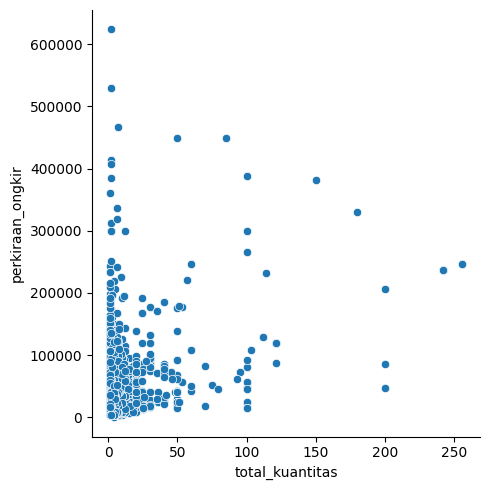

In [18]:
# menampilkan hubungan fitur Total Kuantitas dengan Perkiraan Ongkos Kirim
sns.relplot(x='total_kuantitas', y='perkiraan_ongkir', data=data)

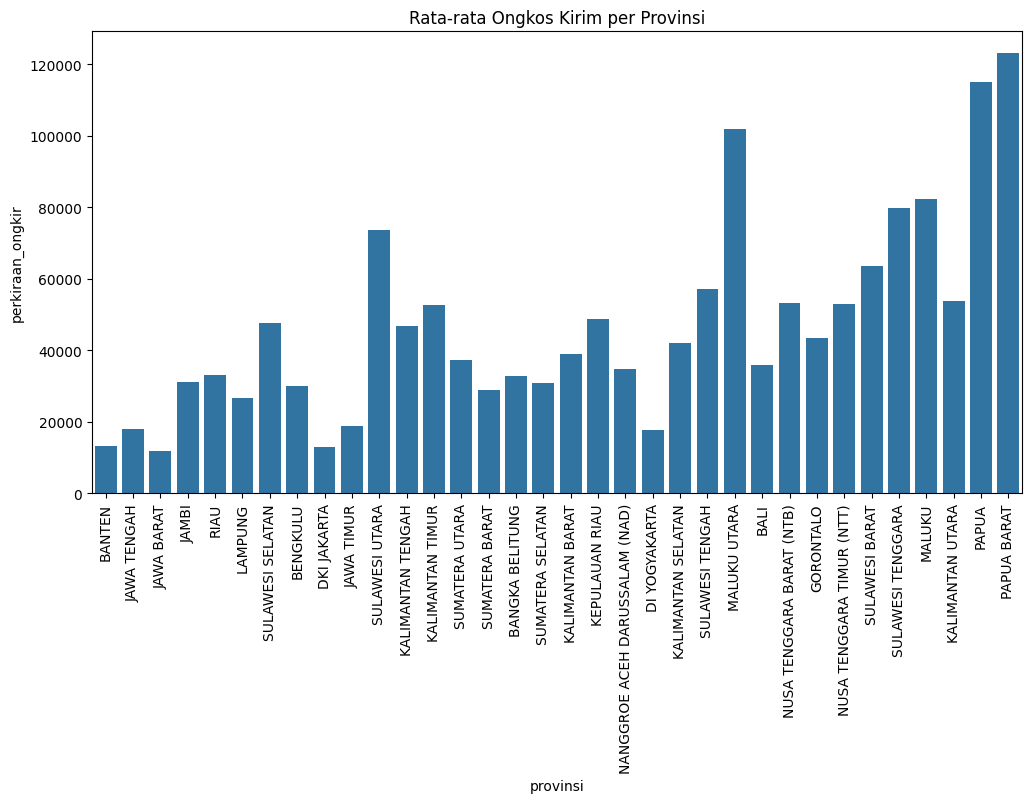

In [19]:
# menampilkan rata-rata 'perkiraan_ongkir' berdasarkan 'provinsi' pembeli
plt.figure(figsize=(12, 6))
sns.barplot(x='provinsi', y='perkiraan_ongkir', data=data, errorbar=None)
plt.xticks(rotation=90)
plt.title("Rata-rata Ongkos Kirim per Provinsi")
plt.show()

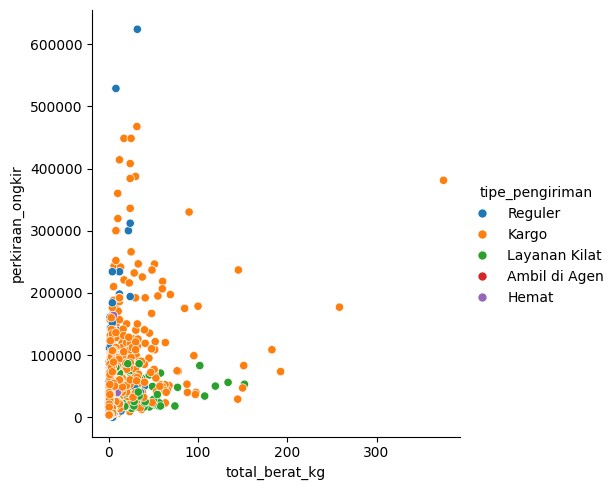

In [20]:
# menampilkan 'total_berat_kg' dengan 'perkiraan_ongkir' dengan (hue) untuk Tipe Pengiriman
sns.relplot(x='total_berat_kg', y='perkiraan_ongkir', hue='tipe_pengiriman', data=data)

Model

In [21]:
# memilih fitur yang digunakan unuk pemodelan
fitur_penting = ['total_berat_kg', 'total_kuantitas', 'provinsi', 'tipe_pengiriman', 'perkiraan_ongkir']

# mengubah fitur 'tipe_pengiriman' dan 'provinsi' ke bilangan biner agar bisa diinputkan model
data = pd.get_dummies(data[fitur_penting], columns=['provinsi', 'tipe_pengiriman'], drop_first=True)

# menentukan fitur dan target
train = data.drop('perkiraan_ongkir', axis=1)
test = data['perkiraan_ongkir']

In [22]:
x_train, x_test, y_train, y_test = train_test_split(train, test, test_size=0.3, random_state=2)

In [23]:
regr = LinearRegression()

In [24]:
regr.fit(x_train, y_train)

LinearRegression()

In [25]:
pred = regr.predict(x_test)

In [26]:
pred

array([ 9671.29689621, 56776.09715257, 26571.32380819, ...,
       33058.41583538, 11403.33701493, 32972.97279368])

In [27]:
regr.score(x_test, y_test)

0.44700049435567146